# Experiment 3: Logistic Regression

**Name:** Koushal Gupta  

## Aim
To implement **Logistic Regression** for binary classification on the **Breast Cancer dataset** (`Malignant` vs `Benign`).

## Concept
Logistic Regression predicts class probabilities between `0` and `1` using the **Sigmoid function**:
$$P(y=1) = \frac{1}{1 + e^{-z}}$$


In [1]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [2]:
# Step 2: Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Target classes:", [str(c) for c in data.target_names])


Dataset shape: (569, 30)
Target classes: ['malignant', 'benign']


In [3]:
# Step 3: Split data and scale features
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [4]:
# Step 4: Train Logistic Regression model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Step 5: Make predictions
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Accuracy: 0.9737

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        43
      benign       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



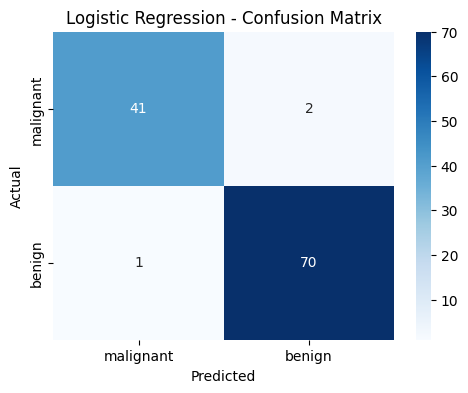

In [5]:
# Step 6: Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## Conclusion
- Logistic Regression achieved high accuracy (~97%+) on the Breast Cancer dataset after feature scaling with `StandardScaler`.
- The confusion matrix shows very few misclassifications between malignant and benign cases.
